# Value of the next item: can household clusters beat the category median?

The suggestion loop asks about a new category and proposes a value. Today that value is the **median of
the category** over all assets of the training households. This notebook tests a different idea:

> Cluster similar households. For a new category, suggest the **median value of that category inside the
> household's cluster**. If a cluster has too few examples of the category, fall back to the overall
> category median.

Nothing here is wired into the app. The notebook prints its results and saves a single file: the fitted best clustering, kept as a record of what was tested. It answers one question: does clustering reduce the error?

**What is predicted.** The value of the item the customer actually documented next (the median value of
the assets created at the first event of the target category), for the same prediction states as the
classifier (`data/processed/model_state.csv`). Vehicles are left out because the loop never suggests them.

**Leakage controls**
- Only the training and validation households are used to compare methods. The test households are read once, at the very end, for the single best configuration.
- All fitting (imputing, scaling, encoding, PCA, clustering, medians) happens on the training part of each fold only. Cross-validation is grouped by `Property_ID`, repeated with different random fold assignments.
- Clusters are built from household features only, never from the value being predicted.

**Methods.** KMeans, Gaussian mixture, Ward hierarchical (all on a PCA-reduced space), average-linkage hierarchical on Gower distance, and DBSCAN on Gower distance, each on four feature sets, plus a random-cluster control.

In [1]:
from pathlib import Path
import sys, time, warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_numeric_dtype
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "modeling"))
from splits import split_properties  # same grouped split as 03_fm_modelling

WORKBOOK = ROOT / "data" / "raw" / "myVal_Synthetic_Datasets_release_v2.xlsx"
MODEL_STATE = ROOT / "data" / "processed" / "model_state.csv"
ARTEFACTS = ROOT / "models" / "value_clusters"   # the only file this notebook writes

N_REPEATS = 3        # repeated grouped 5-fold cross-validation
N_FOLDS = 5
M_MIN = 5            # a cluster must hold at least this many examples of the category, else fall back
K_VALUES = [2, 3, 4, 6, 8]
DBSCAN_EPS = [0.20, 0.25, 0.30]
DBSCAN_MIN_SAMPLES = 8

## 1. Build the target: the value of the item the customer logged next

In [2]:
state = pd.read_csv(MODEL_STATE, parse_dates=["Prediction_Time"])
assets = pd.read_excel(WORKBOOK, sheet_name="assets")
assets["Created_At"] = pd.to_datetime(assets["Created_At"], errors="coerce")
parts = split_properties(state)
DEV_PROPS = parts["train"] | parts["validation"]

# value of the item(s) created at the first event of each (household, category); median if several
first = assets.groupby(["Property_ID", "Category"])["Created_At"].min().rename("t").reset_index()
events = assets.merge(first, on=["Property_ID", "Category"])
events = events[events["Created_At"] == events["t"]]
next_value = events.groupby(["Property_ID", "Category"])["Current_Estimated_Value"].median().rename("next_value").reset_index()

data = state.merge(next_value, left_on=["Property_ID", "Next_Category"], right_on=["Property_ID", "Category"], how="left").drop(columns="Category")
data = data[(data["next_value"] > 0) & (data["Next_Category"] != "Vehicles")].reset_index(drop=True)
data["mean_item_value"] = (data["documented_value_total"] / data["documented_asset_count"]).replace([np.inf, -np.inf], np.nan)
data["log_value"] = np.log(data["next_value"])

dev = data[data["Property_ID"].isin(DEV_PROPS)].reset_index(drop=True)
test = data[data["Property_ID"].isin(parts["test"])].reset_index(drop=True)

# every valued non-vehicle asset: the pool behind the median the live loop uses today
pool = assets[(assets["Category"] != "Vehicles") & (assets["Current_Estimated_Value"] > 0)][["Property_ID", "Category", "Current_Estimated_Value"]].copy()
pool["log_value"] = np.log(pool["Current_Estimated_Value"])

print(f"development rows (train+validation households): {len(dev)}  from {dev['Property_ID'].nunique()} households")
print(f"test rows (read once, at the end):              {len(test)}  from {test['Property_ID'].nunique()} households")
print("\nnext-item value by category (development rows):")
print(dev.groupby("Next_Category")["next_value"].agg(["count", "median", "mean", "max"]).round(0).to_string())

development rows (train+validation households): 364  from 196 households
test rows (read once, at the end):              53  from 36 households

next-item value by category (development rows):
                              count  median    mean      max
Next_Category                                               
Appliances                       65   879.0  1385.0   7500.0
Clothings                        31   200.0  1957.0  15000.0
Electronics                      60   760.0  2130.0  38000.0
Furniture                        73   450.0  1768.0  50000.0
Jewellery and Personal Items     51   750.0  2899.0  22000.0
Other Items                      84   300.0  1812.0  25000.0


## 2. Household features to cluster on

Four feature sets, so we can see what notion of "similar household" matters for value:
- **profile**: who the household is (property, customer and account details)
- **state**: what it has documented so far (counts, value totals, AI aggregates)
- **wealth**: a small set of money-related features
- **all**: profile and state together

In [3]:
STATIC = ["Property_Type", "Occupancy_Type", "Number_Of_Occupants", "Number_Of_Bedrooms", "Property_Valuation_AUD",
          "Is_Home_Insured", "Insurance_Coverage_Type", "Is_Primary", "Age_Band", "Gender", "State", "Membership_Level",
          "Account_Status", "Household_Type", "Income_Band", "Financial_Literacy_Band", "Engagement_Tier", "Tenure_Months",
          "Insurance_Confidence_1_5", "Prior_Claim_Experience", "Underinsurance_Awareness", "Preferred_Channel",
          "Preferred_Explanation_Style", "Notification_Opt_In"]
STATE = [f"documented_count_CAT-00{i}" for i in range(1, 8)] + [
    "documented_asset_count", "documented_category_count", "documented_value_total", "documented_replacement_cost_total",
    "mean_evidence_rating", "mean_item_value", "ai_asset_count", "ai_estimated_value_total", "ai_estimated_value_mean",
    "ai_estimated_value_max"]
WEALTH = ["Property_Valuation_AUD", "Income_Band", "Household_Type", "Number_Of_Bedrooms", "Number_Of_Occupants",
          "Occupancy_Type", "Property_Type", "mean_item_value", "documented_value_total"]
FEATURE_SETS = {"profile": STATIC, "state": STATE, "wealth": WEALTH, "all": STATIC + STATE}
LOG_COLUMNS = {"Property_Valuation_AUD", "documented_value_total", "documented_replacement_cost_total", "mean_item_value",
               "ai_estimated_value_total", "ai_estimated_value_mean", "ai_estimated_value_max"}  # skewed money columns

missing = [c for cols in FEATURE_SETS.values() for c in cols if c not in data.columns]
assert not missing, missing

def prepare(frame, cols):
    """Raw feature frame: booleans and text as strings, skewed money columns on a log scale."""
    out = frame[cols].copy()
    for c in cols:
        if is_bool_dtype(out[c]) or not is_numeric_dtype(out[c]):
            # missing text becomes the literal "nan" on every pandas version (pandas 3 keeps real NaN)
            out[c] = out[c].map(lambda v: "nan" if pd.isna(v) else str(v)).astype(object)
        elif c in LOG_COLUMNS:
            out[c] = np.log1p(out[c].clip(lower=0))
    return out

def split_types(frame):
    num = [c for c in frame.columns if is_numeric_dtype(frame[c])]
    return num, [c for c in frame.columns if c not in num]

def encoder(frame):
    num, cat = split_types(frame)
    return ColumnTransformer([
        ("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
        ("c", Pipeline([("i", SimpleImputer(strategy="most_frequent", missing_values="nan")), ("e", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])

def gower(A, B, ranges):
    """Gower distance (mean over columns of range-scaled numeric gaps and 0/1 category mismatches)."""
    num, cat = split_types(A)
    total = np.zeros((len(A), len(B)))
    count = np.zeros_like(total)
    for c in num:
        d = np.abs(A[c].to_numpy(float)[:, None] - B[c].to_numpy(float)[None, :]) / ranges[c]
        ok = ~np.isnan(d)
        total += np.where(ok, d, 0.0)
        count += ok
    for c in cat:
        a, b = A[c].to_numpy(object)[:, None], B[c].to_numpy(object)[None, :]
        ok = (a != "nan") & (b != "nan")
        total += np.where(ok, (a != b).astype(float), 0.0)
        count += ok
    return total / np.maximum(count, 1)

def ranges_of(frame):
    num, _ = split_types(frame)
    return {c: (frame[c].max() - frame[c].min()) or 1.0 for c in num}

## 3. Clustering methods and the cluster-median prediction

Each method returns the training labels and a function that assigns a new household to a cluster.
Methods without a `predict` (hierarchical, DBSCAN) assign a new household to the cluster of its nearest
training household. DBSCAN marks outliers as `-1`; they use the fallback.

In [4]:
def nearest_centroid_assigner(Z, labels):
    centroids = {l: Z[labels == l].mean(axis=0) for l in np.unique(labels)}
    ids = list(centroids)
    matrix = np.vstack([centroids[l] for l in ids])
    return lambda Zn: np.array(ids)[np.argmin(((Zn[:, None, :] - matrix[None, :, :]) ** 2).sum(axis=2), axis=1)]

def kmeans_method(Ztr, k, seed=0):
    model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Ztr)
    return model.labels_, model.predict, model

def gmm_method(Ztr, k, seed=0):
    model = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-3, n_init=2, random_state=seed).fit(Ztr)
    return model.predict(Ztr), model.predict, model

def ward_method(Ztr, k):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Ztr)
    return labels, nearest_centroid_assigner(Ztr, labels), None

def gower_average_method(Dtr, Dte, k):
    labels = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average").fit_predict(Dtr)
    return labels, labels[np.argmin(Dte, axis=1)]

def dbscan_method(Dtr, Dte, eps):
    labels = DBSCAN(eps=eps, min_samples=DBSCAN_MIN_SAMPLES, metric="precomputed").fit_predict(Dtr)
    return labels, labels[np.argmin(Dte, axis=1)]

def cluster_median_predict(train_labels, train_cat, train_lv, test_labels, test_cat, fallback):
    """Median log-value of (cluster, category) when it has >= M_MIN examples, else the category median."""
    table = pd.DataFrame({"l": train_labels, "c": train_cat, "v": train_lv}).groupby(["l", "c"])["v"].agg(["median", "count"])
    lookup = {k: (r["median"], r["count"]) for k, r in table.iterrows()}
    out = np.empty(len(test_labels))
    used = np.zeros(len(test_labels), bool)
    for i, (l, c) in enumerate(zip(test_labels, test_cat)):
        hit = lookup.get((l, c))
        if l != -1 and hit is not None and hit[1] >= M_MIN:
            out[i], used[i] = hit[0], True
        else:
            out[i] = fallback[c]
    return out, used

def metrics(log_pred, log_true):
    pred, true = np.exp(log_pred), np.exp(log_true)
    err = np.abs(pred - true)
    return {"mean_err_$": err.mean(), "median_err_$": np.median(err),
            "log_error": np.abs(log_pred - log_true).mean(),
            "within_50%": np.mean((pred >= 0.5 * true) & (pred <= 1.5 * true)),
            "within_25%": np.mean((pred >= 0.75 * true) & (pred <= 1.25 * true))}

## 4. Cross-validation

Repeated grouped 5-fold cross-validation on the development households. For every split, every method and
feature set is refit from scratch on the training part. Baselines use the same splits:
- **all-asset median** (what the live loop uses today): median over every valued asset of the training households
- **next-item median**: median of next-item values per category in the training rows
- **random clusters**: the same procedure with random cluster labels, a control for "does the clustering carry any signal?"

In [5]:
y = dev["log_value"].values
cats = dev["Next_Category"].values
props = dev["Property_ID"].values
unique_props = np.array(sorted(set(props)))
n = len(dev)

configs = {}   # (method, feature set, parameter) -> {"pred": repeats x rows, "used": repeats x rows}
def record(key, r, test_idx, pred, used=None):
    slot = configs.setdefault(key, {"pred": np.full((N_REPEATS, n), np.nan), "used": np.zeros((N_REPEATS, n), bool)})
    slot["pred"][r, test_idx] = pred
    if used is not None:
        slot["used"][r, test_idx] = used

started = time.time()
for r in range(N_REPEATS):
    order = np.random.RandomState(r).permutation(unique_props)
    fold_of = {p: i % N_FOLDS for i, p in enumerate(order)}
    folds = np.array([fold_of[p] for p in props])
    for f in range(N_FOLDS):
        te, tr = np.where(folds == f)[0], np.where(folds != f)[0]
        test_props = set(props[te])

        # baselines
        all_asset = pool[~pool["Property_ID"].isin(test_props) & pool["Property_ID"].isin(DEV_PROPS)].groupby("Category")["log_value"].median()
        next_item = pd.Series(y[tr]).groupby(cats[tr]).median()
        overall = np.median(y[tr])
        fb_next = {c: next_item.get(c, overall) for c in set(cats)}
        record(("baseline", "all-asset median (live loop today)", ""), r, te, np.array([all_asset.get(c, overall) for c in cats[te]]))
        record(("baseline", "next-item median", ""), r, te, np.array([fb_next[c] for c in cats[te]]))

        # random-cluster control
        rng = np.random.RandomState(100 + r * 10 + f)
        for k in (3, 6):
            pred, used = cluster_median_predict(rng.randint(0, k, len(tr)), cats[tr], y[tr], rng.randint(0, k, len(te)), cats[te], fb_next)
            record(("control", "random clusters", f"k={k}"), r, te, pred, used)

        for fs_name, cols in FEATURE_SETS.items():
            raw_tr, raw_te = prepare(dev.iloc[tr], cols), prepare(dev.iloc[te], cols)
            enc = encoder(raw_tr)
            Xtr, Xte = enc.fit_transform(raw_tr), enc.transform(raw_te)
            pca = PCA(n_components=min(8, Xtr.shape[1]), random_state=0).fit(Xtr)
            Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
            rg = ranges_of(raw_tr)
            Dtr, Dte = gower(raw_tr, raw_tr, rg), gower(raw_te, raw_tr, rg)

            for k in K_VALUES:
                for method, fit in (("KMeans", lambda: kmeans_method(Ztr, k)), ("GaussianMixture", lambda: gmm_method(Ztr, k)), ("Ward", lambda: ward_method(Ztr, k))):
                    labels, assign, _ = fit()
                    pred, used = cluster_median_predict(labels, cats[tr], y[tr], assign(Zte), cats[te], fb_next)
                    record((method, fs_name, f"k={k}"), r, te, pred, used)
                labels, test_labels = gower_average_method(Dtr, Dte, k)
                pred, used = cluster_median_predict(labels, cats[tr], y[tr], test_labels, cats[te], fb_next)
                record(("Gower-average", fs_name, f"k={k}"), r, te, pred, used)
            for eps in DBSCAN_EPS:
                labels, test_labels = dbscan_method(Dtr, Dte, eps)
                pred, used = cluster_median_predict(labels, cats[tr], y[tr], test_labels, cats[te], fb_next)
                record(("DBSCAN", fs_name, f"eps={eps}"), r, te, pred, used)
    print(f"repeat {r + 1}/{N_REPEATS} done ({time.time() - started:.0f}s)")
print(f"{len(configs)} configurations evaluated")

repeat 1/3 done (3s)


repeat 2/3 done (7s)


repeat 3/3 done (10s)
96 configurations evaluated


### Rule-based groups, like the frontend presets

The web page offers three example households: **Just started**, **Typical household** and **Well documented**.
Here a household is put in one of those groups by how many items it has documented. The anchors are read from the
presets of the original `index.html` on GitHub (`origin/develop`): the sum of each preset's documented counts. A household joins the nearest anchor, and the
suggested value is the median **first-item** value of the category inside the group, falling back to the overall
first-item median when a group has fewer than `M_MIN` examples. Nothing is fitted except those medians, which are
computed on the training part of each fold. A data-driven variant (terciles of documented items) is shown for comparison.

In [6]:
# the three example households of the ORIGINAL page on GitHub (the page now loads real households from the dataset instead)
import subprocess
html = subprocess.run(["git", "show", "origin/develop:index.html"], cwd=ROOT, capture_output=True, text=True, check=True).stdout

def preset_item_count(name):
    # the preset line looks like:  "Just started": {...base, ...cnt([1,0,0,0,0,0,0],[...]), ...
    start = html.index('"' + name + '":')
    first_list = html.index("cnt([", start) + len("cnt([")
    return sum(int(v) for v in html[first_list:html.index("]", first_list)].split(","))

GROUPS = ["Just started", "Typical household", "Well documented"]
ANCHORS = {g: preset_item_count(g) for g in GROUPS}
ANCHOR_VALUES = np.array([ANCHORS[g] for g in GROUPS])
print("anchors read from the original index.html on GitHub (documented items per preset):", ANCHORS)

def frontend_group(item_counts):
    # nearest preset by documented item count (a tie goes to the smaller group)
    return np.array(GROUPS)[np.argmin(np.abs(np.asarray(item_counts)[:, None] - ANCHOR_VALUES[None, :]), axis=1)]

items = dev["documented_asset_count"].values
FRONTEND_KEY = ("Frontend groups", "documented_asset_count", "nearest preset (" + "/".join(map(str, ANCHOR_VALUES)) + " items)")
TERTILE_KEY = ("Tertile groups", "documented_asset_count", "terciles of documented items")
for r in range(N_REPEATS):
    order = np.random.RandomState(r).permutation(unique_props)       # same folds as the cross-validation above
    fold_of = {p: i % N_FOLDS for i, p in enumerate(order)}
    folds = np.array([fold_of[p] for p in props])
    for f in range(N_FOLDS):
        te, tr = np.where(folds == f)[0], np.where(folds != f)[0]
        next_item = pd.Series(y[tr]).groupby(cats[tr]).median()
        fb = {c: next_item.get(c, np.median(y[tr])) for c in set(cats)}
        pred, used = cluster_median_predict(frontend_group(items[tr]), cats[tr], y[tr], frontend_group(items[te]), cats[te], fb)
        record(FRONTEND_KEY, r, te, pred, used)
        cuts = np.quantile(items[tr], [1 / 3, 2 / 3])
        pred, used = cluster_median_predict(np.digitize(items[tr], cuts), cats[tr], y[tr], np.digitize(items[te], cuts), cats[te], fb)
        record(TERTILE_KEY, r, te, pred, used)
print(len(configs), "configurations now evaluated")

anchors read from the original index.html on GitHub (documented items per preset): {'Just started': 1, 'Typical household': 7, 'Well documented': 21}
98 configurations now evaluated


In [7]:
NOT_CLUSTERING = ["baseline", "control", "Frontend groups", "Tertile groups"]
rows = []
for key, slot in configs.items():
    per_repeat = [metrics(slot["pred"][r], y) for r in range(N_REPEATS)]
    avg = {m: np.mean([p[m] for p in per_repeat]) for m in per_repeat[0]}
    rows.append({"method": key[0], "features": key[1] if key[0] != "baseline" else "", "setting": key[2] if key[0] != "baseline" else key[1],
                 **avg, "cluster_used_%": slot["used"].mean() * 100})
results = pd.DataFrame(rows)
results.loc[results["method"] == "baseline", "features"] = ""

show = ["method", "features", "setting", "mean_err_$", "median_err_$", "log_error", "within_50%", "within_25%", "cluster_used_%"]
fmt = {k: v.format for k, v in {"mean_err_$": "{:.0f}", "median_err_$": "{:.0f}", "log_error": "{:.3f}", "within_50%": "{:.1%}", "within_25%": "{:.1%}", "cluster_used_%": "{:.0f}"}.items()}
print("BASELINES, CONTROL AND RULE-BASED GROUPS")
print(results[results["method"].isin(NOT_CLUSTERING)][show].to_string(index=False, formatters=fmt))
print("\nBEST CONFIGURATION OF EACH CLUSTERING METHOD (by log error)")
best_each = results[~results["method"].isin(NOT_CLUSTERING)].sort_values("log_error").groupby("method").head(1).sort_values("log_error")
print(best_each[show].to_string(index=False, formatters=fmt))
print("\nTOP 10 CONFIGURATIONS OVERALL (by log error)")
print(results[~results["method"].isin(NOT_CLUSTERING)].sort_values("log_error").head(10)[show].to_string(index=False, formatters=fmt))

BASELINES, CONTROL AND RULE-BASED GROUPS
         method               features                            setting mean_err_$ median_err_$ log_error within_50% within_25% cluster_used_%
       baseline                        all-asset median (live loop today)       1733          372     1.331      31.2%      15.8%              0
       baseline                                          next-item median       1723          406     1.246      31.5%      16.1%              0
        control        random clusters                                k=3       1748          443     1.286      29.7%      14.2%            100
        control        random clusters                                k=6       1803          440     1.316      28.0%      14.1%             90
Frontend groups documented_asset_count      nearest preset (1/7/21 items)       1746          450     1.260      30.7%      15.5%             96
 Tertile groups documented_asset_count       terciles of documented items       1748     

## 5. Is the best configuration really better? Paired bootstrap over households

With about 360 rows, small differences are noise, and picking the best of ~100 configurations is itself optimistic.
We compare the best configuration with the next-item median using a bootstrap that resamples whole households.

In [8]:
def household_bootstrap(err_a, err_b, groups, draws=2000, seed=0):
    """95% interval of mean(err_a - err_b), resampling households with replacement."""
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "count"])
    s, c = diff["sum"].values, diff["count"].values
    rng = np.random.RandomState(seed)
    idx = rng.randint(0, len(s), size=(draws, len(s)))
    means = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    return (err_a - err_b).mean(), np.percentile(means, [2.5, 97.5])

def abs_log_error(key):
    return np.abs(configs[key]["pred"] - y).mean(axis=0)   # averaged over repeats, one value per row

candidates = results[~results["method"].isin(NOT_CLUSTERING)].sort_values("log_error")
best = candidates.iloc[0]
best_key = (best["method"], best["features"], best["setting"])
base_key = ("baseline", "next-item median", "")
live_key = ("baseline", "all-asset median (live loop today)", "")

print(f"best configuration: {best_key}")
for name, key in (("next-item median", base_key), ("all-asset median (live loop today)", live_key)):
    mean_diff, (lo, hi) = household_bootstrap(abs_log_error(best_key), abs_log_error(key), props)
    verdict = "clearly better" if hi < 0 else "clearly worse" if lo > 0 else "not distinguishable from zero"
    print(f"  vs {name:36s}: change in log error {mean_diff:+.3f}  (95% interval {lo:+.3f} to {hi:+.3f})  -> {verdict}")

mean_diff, (lo, hi) = household_bootstrap(abs_log_error(base_key), abs_log_error(live_key), props)
verdict = "clearly better" if hi < 0 else "clearly worse" if lo > 0 else "not distinguishable from zero"
print()
print(f"the change being adopted, next-item median vs all-asset median (live loop today): change in log error {mean_diff:+.3f}  (95% interval {lo:+.3f} to {hi:+.3f})  -> {verdict}")

best configuration: ('KMeans', 'all', 'k=2')
  vs next-item median                    : change in log error -0.005  (95% interval -0.040 to +0.029)  -> not distinguishable from zero
  vs all-asset median (live loop today)  : change in log error -0.090  (95% interval -0.156 to -0.031)  -> clearly better

the change being adopted, next-item median vs all-asset median (live loop today): change in log error -0.086  (95% interval -0.138 to -0.033)  -> clearly better


### Error margins per method

Each score above is one number from one set of 364 rows. To show how much it could move, we resample whole households
with replacement 1,000 times and recompute every score; the 2.5th and 97.5th percentiles give a 95% margin.

In [9]:
def bootstrap_metrics(key, draws=1000, seed=1):
    pred = configs[key]["pred"]                      # repeats x rows
    rows_by_household = [np.array(v) for v in pd.Series(np.arange(n)).groupby(props).apply(list).values]
    rng = np.random.RandomState(seed)
    out = []
    for _ in range(draws):
        pick = rng.randint(0, len(rows_by_household), len(rows_by_household))
        idx = np.concatenate([rows_by_household[i] for i in pick])
        per_repeat = [metrics(pred[r][idx], y[idx]) for r in range(N_REPEATS)]
        out.append({m: np.mean([p[m] for p in per_repeat]) for m in per_repeat[0]})
    return pd.DataFrame(out)

named = {"Today: all-asset median": live_key, "Planned: next-item median": base_key,
         f"{best_key[0]} ({best_key[1]}, {best_key[2]})": best_key,
         "Frontend groups (Just started / Typical / Well documented)": FRONTEND_KEY,
         "Tertile groups": TERTILE_KEY}
margin_rows = []
for label, key in named.items():
    boot = bootstrap_metrics(key)
    point = {m: np.mean([metrics(configs[key]["pred"][r], y)[m] for r in range(N_REPEATS)]) for m in boot.columns}
    for m in boot.columns:
        lo, hi = np.percentile(boot[m], [2.5, 97.5])
        margin_rows.append({"method": label, "metric": m, "value": point[m], "low_95": lo, "high_95": hi})
margins = pd.DataFrame(margin_rows)

def show_value(metric, v):
    return f"{v:.1%}" if metric.startswith("within") else f"{v:.3f}" if metric == "log_error" else f"{v:,.0f}"
for label in named:
    print(label)
    for _, r in margins[margins["method"] == label].iterrows():
        print(f"   {r['metric']:14s} {show_value(r['metric'], r['value']):>8s}   95% margin {show_value(r['metric'], r['low_95'])} to {show_value(r['metric'], r['high_95'])}")

Today: all-asset median
   mean_err_$        1,733   95% margin 1,201 to 2,318
   median_err_$        372   95% margin 324 to 420
   log_error         1.331   95% margin 1.204 to 1.474
   within_50%        31.2%   95% margin 27.0% to 35.8%
   within_25%        15.8%   95% margin 12.2% to 19.3%
Planned: next-item median
   mean_err_$        1,723   95% margin 1,192 to 2,303
   median_err_$        406   95% margin 323 to 485
   log_error         1.246   95% margin 1.122 to 1.381
   within_50%        31.5%   95% margin 27.2% to 36.0%
   within_25%        16.1%   95% margin 12.6% to 19.7%
KMeans (all, k=2)
   mean_err_$        1,725   95% margin 1,196 to 2,299
   median_err_$        419   95% margin 372 to 500
   log_error         1.241   95% margin 1.120 to 1.372
   within_50%        31.0%   95% margin 26.6% to 35.4%
   within_25%        16.9%   95% margin 13.4% to 20.5%
Frontend groups (Just started / Typical / Well documented)
   mean_err_$        1,746   95% margin 1,224 to 2,308
   me

### The frontend groups: sizes and medians

In [10]:
group_of = frontend_group(items)
print("development rows per group:  ", pd.Series(group_of).value_counts().reindex(GROUPS).to_dict())
print("households per group:        ", {g: dev.loc[group_of == g, "Property_ID"].nunique() for g in GROUPS})
print("documented items per group:  ", {g: (int(items[group_of == g].min()), int(items[group_of == g].max())) for g in GROUPS})
table = pd.DataFrame({"group": group_of, "category": cats, "v": y}).groupby(["category", "group"])["v"].agg(["median", "count"]).reset_index()
table["median_value"] = np.exp(table["median"]).round(0)
table["uses_group_median"] = table["count"] >= M_MIN
medians_t = table.pivot(index="category", columns="group", values="median_value").reindex(columns=GROUPS)
counts_t = table.pivot(index="category", columns="group", values="count").reindex(columns=GROUPS)
print("\nfirst-item median by group (fitted on all development rows):")
print(medians_t.to_string())
print("\nexamples behind each value (fewer than", M_MIN, "means the overall first-item median is used instead):")
print(counts_t.fillna(0).astype(int).to_string())

development rows per group:   {'Just started': 241, 'Typical household': 90, 'Well documented': 33}
households per group:         {'Just started': 171, 'Typical household': 70, 'Well documented': 24}
documented items per group:   {'Just started': (1, 4), 'Typical household': (5, 14), 'Well documented': (15, 80)}

first-item median by group (fitted on all development rows):
group                         Just started  Typical household  Well documented
category                                                                      
Appliances                           875.0              937.0            450.0
Clothings                            130.0             1000.0            200.0
Electronics                          799.0              120.0            400.0
Furniture                            399.0              474.0            329.0
Jewellery and Personal Items        1350.0              497.0            599.0
Other Items                          199.0              374.0          

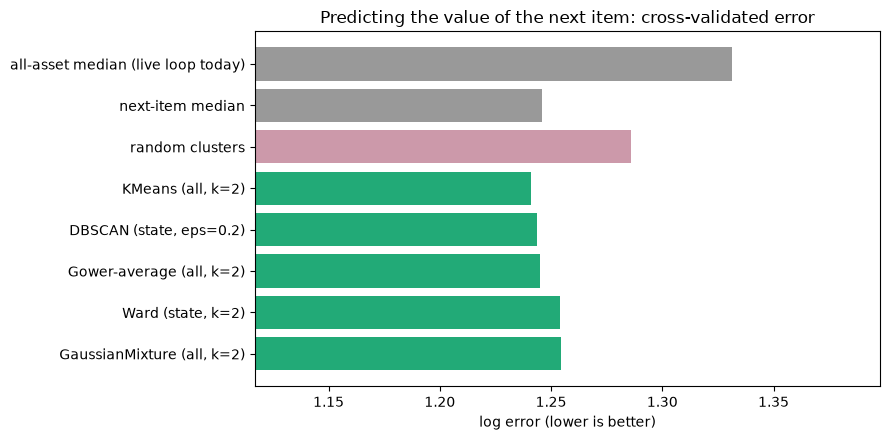

In [11]:
plot = pd.concat([results[results["method"] == "baseline"].assign(label=lambda d: d["setting"]),
                  results[results["method"] == "control"].sort_values("log_error").head(1).assign(label="random clusters"),
                  best_each.assign(label=lambda d: d["method"] + " (" + d["features"] + ", " + d["setting"] + ")")])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot["label"], plot["log_error"], color=["#999"] * 2 + ["#c9a"] + ["#2a7"] * len(best_each))
ax.invert_yaxis(); ax.set_xlabel("log error (lower is better)")
ax.set_title("Predicting the value of the next item: cross-validated error")
ax.set_xlim(plot["log_error"].min() * 0.9, plot["log_error"].max() * 1.05)
plt.tight_layout(); plt.show()

## 6. What do the best clusters look like?

Refit the best configuration on all development rows and describe each cluster.

In [12]:
def fit_final(method, fs_name, setting, train_frame, train_cats, train_lv):
    """Fit the full pipeline on all rows given; returns everything needed to assign and predict."""
    cols = FEATURE_SETS[fs_name]
    raw = prepare(train_frame, cols)
    enc = encoder(raw)
    X = enc.fit_transform(raw)
    pca = PCA(n_components=min(8, X.shape[1]), random_state=0).fit(X)
    Z = pca.transform(X)
    rg = ranges_of(raw)
    art = {"method": method, "features": fs_name, "setting": setting, "columns": cols, "encoder": enc, "pca": pca, "ranges": rg}
    value = float(setting.split("=")[1])
    if method in ("KMeans", "GaussianMixture", "Ward"):
        k = int(value)
        labels, assign, model = {"KMeans": lambda: kmeans_method(Z, k), "GaussianMixture": lambda: gmm_method(Z, k), "Ward": lambda: ward_method(Z, k)}[method]()
        art["model"] = model
        art["centroids"] = {int(l): Z[labels == l].mean(axis=0) for l in np.unique(labels)}
    else:
        D = gower(raw, raw, rg)
        labels = (AgglomerativeClustering(n_clusters=int(value), metric="precomputed", linkage="average").fit_predict(D) if method == "Gower-average"
                  else DBSCAN(eps=value, min_samples=DBSCAN_MIN_SAMPLES, metric="precomputed").fit_predict(D))
        art["train_raw"], art["train_labels"] = raw, labels
    art["labels"] = labels
    next_item = pd.Series(train_lv).groupby(train_cats).median()
    art["fallback"] = {c: float(next_item.get(c, np.median(train_lv))) for c in set(train_cats)}
    art["overall_fallback"] = float(np.median(train_lv))
    table = pd.DataFrame({"l": labels, "c": train_cats, "v": train_lv}).groupby(["l", "c"])["v"].agg(["median", "count"]).reset_index()
    art["cluster_medians"] = {(int(r.l), r.c): (float(np.exp(r["median"])), int(r["count"])) for _, r in table.iterrows()}
    art["m_min"] = M_MIN
    return art

def assign_and_predict(art, frame, cats_new):
    raw = prepare(frame, art["columns"])
    if art["method"] in ("KMeans", "GaussianMixture"):
        labels = art["model"].predict(art["pca"].transform(art["encoder"].transform(raw)))
    elif art["method"] == "Ward":
        Z = art["pca"].transform(art["encoder"].transform(raw))
        ids = list(art["centroids"]); M = np.vstack([art["centroids"][i] for i in ids])
        labels = np.array(ids)[np.argmin(((Z[:, None, :] - M[None, :, :]) ** 2).sum(axis=2), axis=1)]
    else:
        labels = art["train_labels"][np.argmin(gower(raw, art["train_raw"], art["ranges"]), axis=1)]
    out = np.empty(len(frame)); used = np.zeros(len(frame), bool)
    for i, (l, c) in enumerate(zip(labels, cats_new)):
        hit = art["cluster_medians"].get((int(l), c))
        if l != -1 and hit is not None and hit[1] >= art["m_min"]:
            out[i], used[i] = np.log(hit[0]), True
        else:
            out[i] = np.log(art["fallback"].get(c, np.exp(art["overall_fallback"])))
    return out, used, labels

art = fit_final(best["method"], best["features"], best["setting"], dev, cats, y)
profile = dev.assign(cluster=art["labels"])
summary = profile.groupby("cluster").agg(households=("Property_ID", "nunique"), rows=("Property_ID", "size"),
                                         property_valuation=("Property_Valuation_AUD", "median"),
                                         mean_item_value=("mean_item_value", "median"),
                                         items_documented=("documented_asset_count", "median"),
                                         next_item_value=("next_value", "median"))
summary["most_common_next_category"] = profile.groupby("cluster")["Next_Category"].agg(lambda s: s.value_counts().index[0])
print(f"best configuration: {best_key}")
print(summary.round(0).to_string())
print("\nmedian next-item value by cluster and category (blank = fewer than the minimum examples):")
medians = pd.DataFrame([{"cluster": l, "category": c, "median_value": v, "n": nn} for (l, c), (v, nn) in art["cluster_medians"].items() if nn >= M_MIN])
print(medians.pivot(index="cluster", columns="category", values="median_value").round(0).to_string() if len(medians) else "no cluster-category cell has enough examples")

best configuration: ('KMeans', 'all', 'k=2')
         households  rows  property_valuation  mean_item_value  items_documented  next_item_value most_common_next_category
cluster                                                                                                                    
0                83   144            113757.0           1645.0               8.0            500.0               Other Items
1               153   220            104680.0            800.0               1.0            500.0                 Furniture

median next-item value by cluster and category (blank = fewer than the minimum examples):
category  Appliances  Clothings  Electronics  Furniture  Jewellery and Personal Items  Other Items
cluster                                                                                           
0              850.0      671.0        399.0      740.0                         600.0        350.0
1              889.0      100.0        800.0      349.0                

## 7. One-time check on the untouched test households

The test households were not used to choose anything. This is a single evaluation of the best configuration against the baselines.
With few test rows it is noisy and only a sanity check.

In [13]:
dev_pool = pool[pool["Property_ID"].isin(DEV_PROPS)].groupby("Category")["log_value"].median()
next_item_dev = pd.Series(y).groupby(cats).median()
yt, ct = test["log_value"].values, test["Next_Category"].values
pred_cluster, used, _ = assign_and_predict(art, test, ct)
final = pd.DataFrame({
    "all-asset median (live loop today)": metrics(np.array([dev_pool.get(c, np.median(y)) for c in ct]), yt),
    "next-item median": metrics(np.array([next_item_dev.get(c, np.median(y)) for c in ct]), yt),
    f"best clusters {best_key[0]} ({best_key[1]}, {best_key[2]})": metrics(pred_cluster, yt),
}).T
print(f"test rows: {len(test)}   (best configuration used its cluster median for {used.mean():.0%} of them)")
print(final.to_string(float_format=lambda v: f"{v:,.3f}" if v < 10 else f"{v:,.0f}"))

test rows: 53   (best configuration used its cluster median for 100% of them)
                                    mean_err_$  median_err_$  log_error  within_50%  within_25%
all-asset median (live loop today)       1,245           550      1.379       0.189       0.075
next-item median                         1,221           590      1.312       0.208       0.094
best clusters KMeans (all, k=2)          1,226           601      1.349       0.245       0.113


## 8. Keep the best clustering as a record

The fitted best configuration is saved as a record of what was tested. The web app does not use it.

In [14]:
ARTEFACTS.mkdir(parents=True, exist_ok=True)
joblib.dump(art, ARTEFACTS / "best_value_clusters.joblib")
print("saved the fitted best clustering", best_key, "to", ARTEFACTS / "best_value_clusters.joblib")

saved the fitted best clustering ('KMeans', 'all', 'k=2') to /Users/ananya/Desktop/MDSI/Capstone/my_val_capstone_01/models/value_clusters/best_value_clusters.joblib
